# Train a BPE tokenizer

**Byte Pair Encoding** starts with one token per UTF-8 byte. To learn a longer token, find the most frequent adjacent pair, merge it, then count again. The result is a vocabulary and an ordered list of merge rules.

In [10]:
corpus = [
    "banana", "banana", "banana",
    "bandana", "bandana", "ananas",
    "banana bread", "bandana blue",
]

print(list("banana".encode("utf-8")))

[98, 97, 110, 97, 110, 97]


## One merge: `a` + `n`

The pair `(97, 110)` occurs 16 times in this corpus. Give it token ID `256`, the first ID after the 256 base bytes. Replace both occurrences in `banana`.

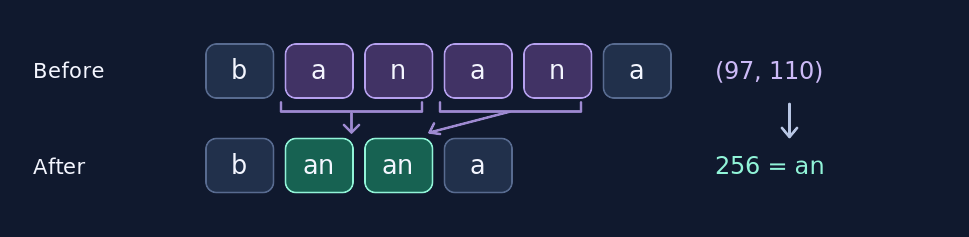

## Count and replace

Count pairs inside each row, never across rows. When replacing, scan left to right and skip both tokens of a match. A token can’t be used by two replacements in the same pass.

In [11]:
from collections import Counter


def count_pairs(rows):
    return Counter(pair for row in rows for pair in zip(row, row[1:]))


def merge(ids, pair, new_id):
    result = []
    i = 0
    while i < len(ids):
        if i + 1 < len(ids) and (ids[i], ids[i + 1]) == pair:
            result.append(new_id)
            i += 2
        else:
            result.append(ids[i])
            i += 1
    return result

## Train

A new token stores the concatenated bytes of its two parts. Later merges can use tokens learned earlier: `ban` + `ana` becomes `banana`. This toy trainer can merge across spaces within a row.

In [12]:
num_merges = 10
rows = [list(text.encode("utf-8")) for text in corpus]
vocab = {i: bytes([i]) for i in range(256)}
merges = []

for _ in range(num_merges):
    counts = count_pairs(rows)
    if not counts:
        break
    (left, right), count = counts.most_common(1)[0]
    pair = (left, right)
    new_id = len(vocab)
    vocab[new_id] = vocab[left] + vocab[right]
    merges.append((pair, new_id))
    rows = [merge(row, pair, new_id) for row in rows]
    print(f"{vocab[left]!r} + {vocab[right]!r} → {vocab[new_id]!r}  (ID {new_id}, count {count})")

b'a' + b'n' → b'an'  (ID 256, count 16)
b'an' + b'a' → b'ana'  (ID 257, count 8)
b'b' + b'an' → b'ban'  (ID 258, count 7)
b'ban' + b'ana' → b'banana'  (ID 259, count 4)
b'ban' + b'd' → b'band'  (ID 260, count 3)
b'band' + b'ana' → b'bandana'  (ID 261, count 3)
b' ' + b'b' → b' b'  (ID 262, count 2)
b'an' + b'ana' → b'anana'  (ID 263, count 1)
b'anana' + b's' → b'ananas'  (ID 264, count 1)
b'banana' + b' b' → b'banana b'  (ID 265, count 1)


## Encode and decode new text

For new text, replay the learned rules in order. To decode, join the token bytes **before** decoding UTF-8: an emoji may span several tokens.

In [13]:
def encode(text):
    ids = list(text.encode("utf-8"))
    for pair, new_id in merges:
        ids = merge(ids, pair, new_id)
    return ids


def decode(ids):
    return b"".join(vocab[token_id] for token_id in ids).decode("utf-8")


text = "banana bandana 🍌"
ids = encode(text)
print("IDs:    ", ids)
print("Pieces: ", [vocab[i] for i in ids])
print("Decoded:", decode(ids))
print(f"{len(text.encode('utf-8'))} bytes → {len(ids)} tokens")
assert decode(ids) == text

IDs:     [259, 32, 261, 32, 240, 159, 141, 140]
Pieces:  [b'banana', b' ', b'bandana', b' ', b'\xf0', b'\x9f', b'\x8d', b'\x8c']
Decoded: banana bandana 🍌
19 bytes → 8 tokens


Try setting `num_merges` to `0` or `3` and rerun all cells. What changes about the token IDs? What stays the same after decoding?